# Fig. 1: premise of Raman-based APC and soft-sensor recalibration.

- (a) Peak PAA per batch, Raman off vs. on, with the toxicity threshold.
- (b) Final penicillin yield distributions, Raman off vs. on.
- (c) Soft-sensor prediction at a true PAA of 2,400 mg/L vs. PAA spread in the recalibration set.
- (d) RMSEP (left axis) and R^2 (right axis) over the same sweep, with the R^2 acceptance gate.
Inputs: raman_onoff.npz (panels a, b) and e4_unified.json (panels c, d).
Style: 17 x 11 cm, DejaVu Sans, title 6.5 / text 5.5 / ticks 5.0 pt; accent colours
slate blue #46618a (Raman on, soft sensor, RMSEP) and rust #a35a3c (R^2, acceptance gate).

In [1]:
import sys; sys.path.insert(0, '..')          # repository root, for paths.py
from paths import DATA, OUTD                   # data/ and output/

In [2]:
# -*- coding: utf-8 -*-
"""Fig. 1 of the manuscript: premise of Raman-based APC and soft-sensor recalibration.

(a) Peak PAA per batch, Raman off vs. on, with the toxicity threshold.
(b) Final penicillin yield distributions, Raman off vs. on.
(c) Soft-sensor prediction at a true PAA of 2,400 mg/L vs. PAA spread in the recalibration set.
(d) RMSEP (left axis) and R^2 (right axis) over the same sweep, with the R^2 acceptance gate.
Inputs: raman_onoff.npz (panels a, b) and e4_unified.json (panels c, d).
Style: 17 x 11 cm, DejaVu Sans, title 6.5 / text 5.5 / ticks 5.0 pt; accent colours
slate blue #46618a (Raman on, soft sensor, RMSEP) and rust #a35a3c (R^2, acceptance gate).
"""
import warnings; warnings.filterwarnings('ignore')
import json, numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, NullFormatter, FuncFormatter
from scipy.stats import gaussian_kde

INK, GRY, FILL = '#23201a', '#8f897d', '#f4f2ee'
BLU, RUST = '#46618a', '#a35a3c'
plt.rcParams.update({'font.family': ['DejaVu Sans'], 'font.size': 5.5, 'axes.titlesize': 6.5,
                     'axes.labelsize': 5.5, 'xtick.labelsize': 5.0, 'ytick.labelsize': 5.0, 'axes.linewidth': 0.5,
                     'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 2,
                     'xtick.minor.size': 0, 'legend.fontsize': 5.0, 'mathtext.default': 'regular', 'axes.unicode_minus': True})
G = DATA
D = DATA
OUT = OUTD + 'fig1'
PAA_TOX, LOWYIELD, TRUE = 2400.0, 2130.0, 2400.0

d = np.load(G + 'raman_onoff.npz')
off, on, offp, onp = d['off'], d['on'], d['off_paa'], d['on_paa']
m = np.isfinite(off) & np.isfinite(on); off, on, offp, onp = off[m], on[m], offp[m], onp[m]
e4 = json.load(open(D + 'e4_unified.json'))
SPT, R2_GATE = e4['SP'], e4['R2_GATE']
rows = [r for r in e4['curve'] if '2400' in r['bias'] or 2400 in r['bias']]
_b = lambda r: r['bias'].get('2400', r['bias'].get(2400))
sx = np.array([r['cal_std'] for r in rows]); read = np.array([TRUE * (1 + _b(r)) for r in rows])
rm = np.array([r['RMSEP'] for r in rows]); r2 = np.array([r['R2'] for r in rows])
XLO, XHI = sx.min() / 1.6, sx.max() * 1.6
XT = [t for t in (1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000) if XLO < t < XHI]

def style(a, right=False):
    for sp in ('top',) + (() if right else ('right',)): a.spines[sp].set_visible(False)
    for sp in a.spines.values(): sp.set_color(INK)
    a.tick_params(colors=INK)
def title(a, s): a.set_title(s, loc='left', fontweight='bold', color=INK, pad=4)
def logx(a):
    a.set_xscale('log'); a.set_xlim(XLO, XHI)
    a.xaxis.set_major_locator(FixedLocator(XT)); a.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    a.xaxis.set_minor_locator(FixedLocator([])); a.xaxis.set_minor_formatter(NullFormatter())
LEG = dict(frameon=False, handlelength=1.8, borderaxespad=0.2, labelspacing=0.35)

fig, axs = plt.subplots(2, 2, figsize=(17 / 2.54, 11 / 2.54), facecolor='white',
                        gridspec_kw=dict(wspace=0.32, hspace=0.48, left=0.075, right=0.93, top=0.95, bottom=0.09))
(A, B), (C, E) = axs
for a in (A, B, C): style(a)

In [3]:
# (a) Peak PAA per batch
pb = np.linspace(0, 8000, 42)
A.hist(offp, bins=pb, color=GRY, alpha=.55, lw=0, label=f'Raman off (n = {len(offp)})')
A.hist(onp, bins=pb, color=BLU, alpha=.75, lw=0, label=f'Raman on (n = {len(onp)})')
A.axvline(PAA_TOX, color=INK, ls=(0, (3, 2.2)), lw=0.7, label='Toxicity threshold')
A.set_xlim(0, 8000); A.set_xlabel('Peak PAA (mg L$^{-1}$)', color=INK); A.set_ylabel('Batches', color=INK)
A.legend(loc='upper right', **LEG); title(A, '(a)')

In [4]:
# (b) Final yield distribution
yb = np.linspace(1000, 5000, 42); xx = np.linspace(1000, 5000, 800)
B.hist(off, bins=yb, density=True, color=GRY, alpha=.35, lw=0)
B.hist(on, bins=yb, density=True, color=BLU, alpha=.35, lw=0)
B.plot(xx, gaussian_kde(off)(xx), color=GRY, lw=1.0, label='Raman off')
B.plot(xx, gaussian_kde(on)(xx), color=BLU, lw=1.0, label='Raman on')
B.axvline(LOWYIELD, color=INK, ls=(0, (1, 1.2)), lw=0.7, label='Low-yield boundary')
B.set_xlim(1000, 5000); B.set_ylim(0, B.get_ylim()[1] * 1.25)
B.set_xlabel('Final penicillin (kg)', color=INK); B.set_ylabel('Density (10$^{-3}$ kg$^{-1}$)', color=INK)
B.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v * 1e3:g}'))          # move the 1e-3 offset into the unit label so it does not overlap the title
B.legend(loc='upper right', **LEG); title(B, '(b)')

In [5]:
# (c) Recalibrated soft-sensor prediction at true PAA 2,400; same sweep and x axis as (d)
C.axhline(TRUE, color=INK, lw=0.9, label='True PAA')
C.axhline(SPT, color=GRY, ls=(0, (3, 2.2)), lw=0.7, label='APC set-point')
C.plot(sx[:-1], read[:-1], 'o-', color=BLU, lw=0.9, ms=3.2, mec='white', mew=0.5, zorder=4, label='Recalibrated soft sensor')
C.plot(sx[-2:], read[-2:], ls=(0, (1, 1.2)), color=BLU, lw=0.8, zorder=3)
C.plot(sx[-1:], read[-1:], 'o', color=BLU, ms=3.2, mec='white', mew=0.5, zorder=4)
logx(C); C.set_ylim(min(SPT - 80, read.min() - 80), max(TRUE + 420, read.max() + 120))
C.set_xlabel('PAA spread in the recalibration set, $\\sigma$ (mg L$^{-1}$)', color=INK)
C.set_ylabel('Predicted PAA (mg L$^{-1}$)', color=INK)
C.legend(loc='upper left', **LEG); title(C, '(c)')

In [6]:
# (d) RMSEP (left) and R² (right)
style(E, right=True); E2 = E.twinx(); style(E2, right=True); E2.spines['left'].set_visible(False)
E2.axhline(R2_GATE, color=RUST, ls=(0, (3, 2.2)), lw=0.7, zorder=3)
E2.plot(sx[:-1], r2[:-1], 'D-', color=RUST, lw=0.9, ms=2.8, mec='white', mew=0.5, zorder=5)
E2.plot(sx[-2:], r2[-2:], ls=(0, (1, 1.2)), color=RUST, lw=0.8, zorder=4)
E2.plot(sx[-1:], r2[-1:], 'D', color=RUST, ms=2.8, mec='white', mew=0.5, zorder=5)
E2.set_ylim(min(-.35, r2.min() - .1), 1.42); E2.set_ylabel('$R^2$', color=RUST); E2.tick_params(axis='y', colors=RUST)
E2.spines['right'].set_color(RUST)
E.plot(sx[:-1], rm[:-1], 'o-', color=BLU, lw=0.9, ms=3.2, mec='white', mew=0.5, zorder=5)
E.plot(sx[-2:], rm[-2:], ls=(0, (1, 1.2)), color=BLU, lw=0.8, zorder=4)
E.plot(sx[-1:], rm[-1:], 'o', color=BLU, ms=3.2, mec='white', mew=0.5, zorder=5)
E.set_ylim(-rm.max() * .05, rm.max() * 1.9); E.set_ylabel('RMSEP (mg L$^{-1}$)', color=BLU)
E.tick_params(axis='y', colors=BLU); E.spines['left'].set_color(BLU); E.spines['right'].set_visible(False)
logx(E); E.set_xlabel('PAA spread in the recalibration set, $\\sigma$ (mg L$^{-1}$)', color=INK)
E.legend([Line2D([], [], marker='o', color=BLU, lw=0.9, ms=3.2, mec='white', mew=0.5),
          Line2D([], [], marker='D', color=RUST, lw=0.9, ms=2.8, mec='white', mew=0.5),
          Line2D([], [], color=RUST, ls=(0, (3, 2.2)), lw=0.7),
          Line2D([], [], color=GRY, ls=(0, (1, 1.2)), lw=0.8)],
         ['RMSEP', '$R^2$', '$R^2$ acceptance', 'Not sampled'], loc='upper left', **LEG)
title(E, '(d)')

for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}.{ext}', facecolor='white', **kw)
print('saved', OUT, f'| above threshold {100*(offp>PAA_TOX).mean():.0f}%→{100*(onp>PAA_TOX).mean():.0f}%  yield {off.mean():.0f}→{on.mean():.0f}  readout {read.min():.0f}~{read.max():.0f}  gate {int((r2>R2_GATE).sum())}/{len(r2)}')

saved ../output/fig1 | above threshold 69%→0%  yield 2894→3481  readout 1255~2397  gate 2/11


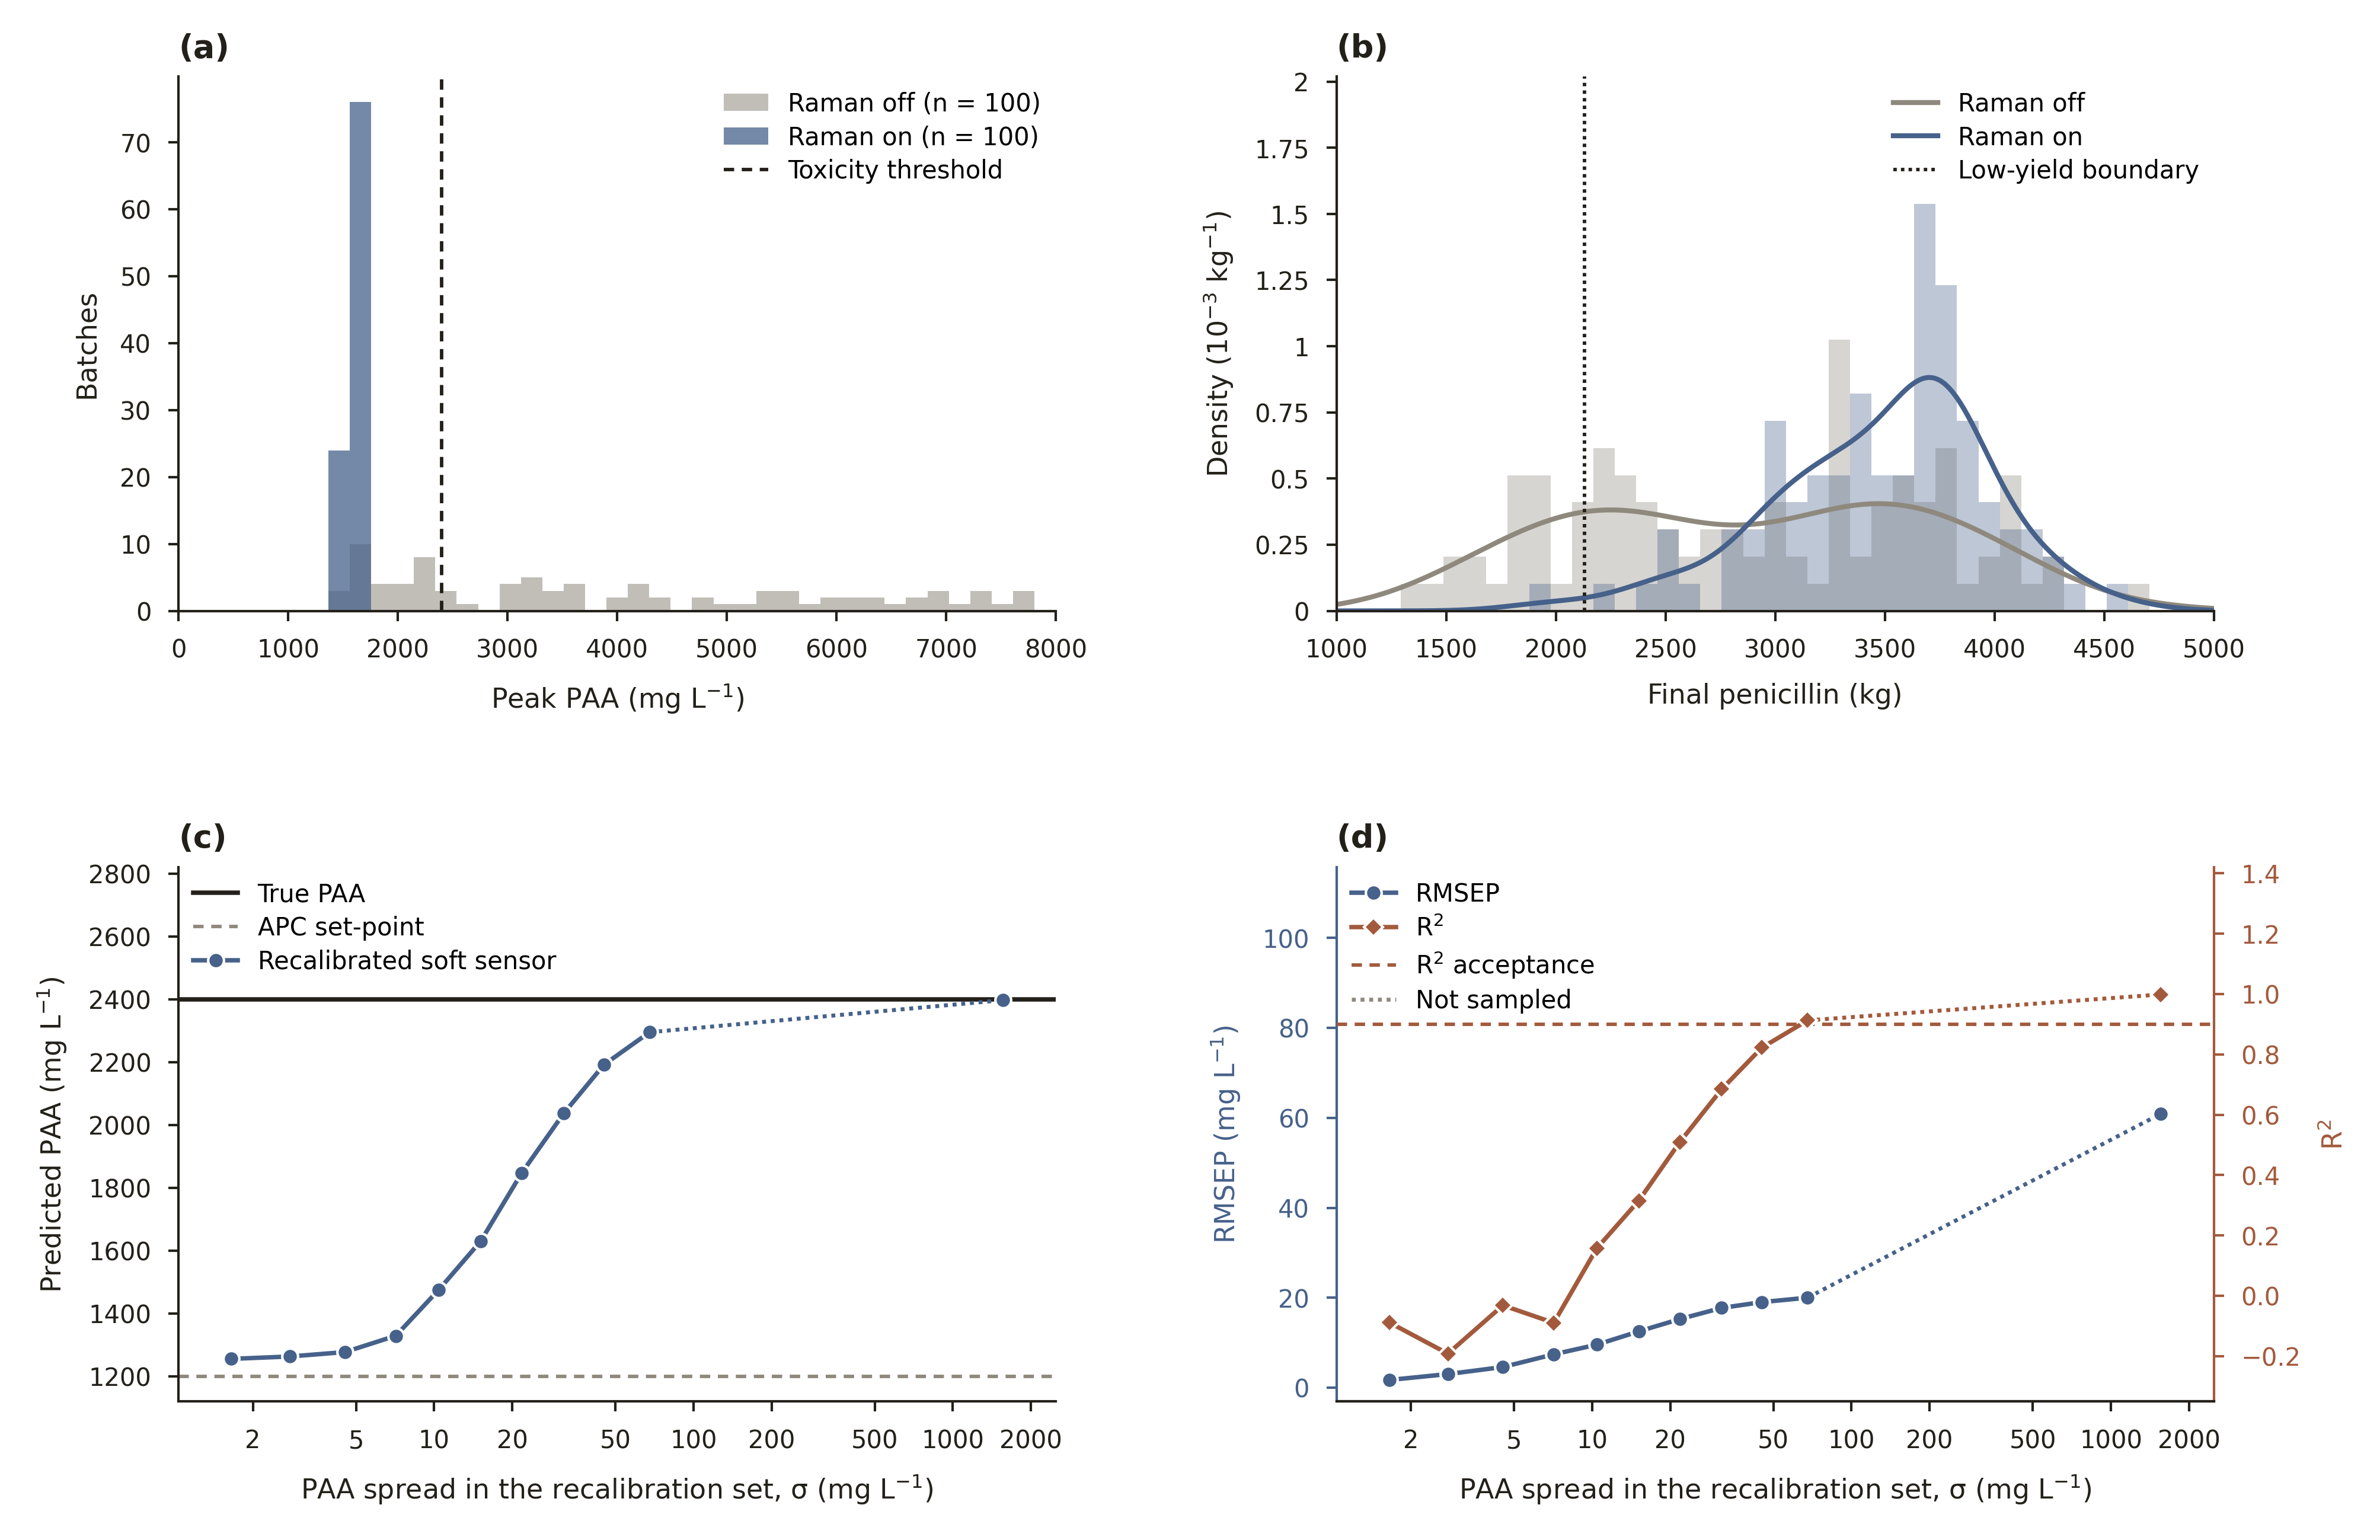

In [7]:
from IPython.display import Image
Image(OUTD + 'fig1.png', width=900)